# Homogeneous emitting cylinder

A uniform cylinder ($r < 1$, $\rho\kappa = 10$, $aT^4 = 1$) in vacuum on a Cartesian mesh, the
2-D analogue of the homogeneous sphere of the IDORT paper (Ma et al. 2025, sec. 4.1.2) and
Jiang (2021, ApJS 253, 49, sec. 4.6), with the production keys (`decks/idort_cylinder.athinput`).
The box is $[-4, 4]^2$, periodic in $y$ (a row of cylinders, period 8). E and the flux along
$y = 0$ are compared with the exact transport solution (`ref/idort_cylinder_exact.npz`).
Criteria: L1 of E inside and outside and of F outside within 5 % of the reference values
(`ref/references.json`). Code units.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
ATHENAK = os.path.abspath(os.environ.get('ATHENAK', '../../athenak'))   # your athenak checkout
sys.path.insert(0, os.path.join(ATHENAK, 'tests/vet_clean/notebooks'))
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', os.path.join(ATHENAK, 'build_tests/src/athena')))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary $ATHENA_EXE 
runs   runs


In [2]:
TESTS = ['idort_cylinder']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

running: python3 $ATHENAK/tests/vet_clean/run_tests.py --exe $ATHENA_EXE --only idort_cylinder --keep --workdir runs --threads 4 --record runs/idort_cylinder.json


clean VET test suite: 1 tests, full, 56 at a time x 4 threads, binary $ATHENA_EXE
PASS idort_cylinder       22 s  E_in 0.000518 E_out 0.013 F_out 0.205
1 passed, 0 failed, 22 s



## Emitting cylinder

E and the flux $F_x/c$ along $y = 0$ against the exact transport solution. E agrees to
1.3 % outside the cylinder; the moment flux in the vacuum outside is about 20 % above the
exact flux (`F_out`, a regression reference).

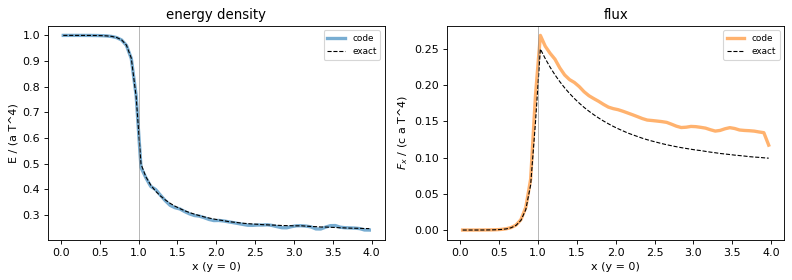

PASS idort_cylinder   criterion {"near": {"E_in": [0.000518, 0.05], "E_out": [0.013, 0.05], "F_out": [0.205, 0.05]}}


True

In [3]:
d = os.path.join(WORK, 'idort_cylinder', 'run')
m, (x1, x2, _) = vett.last_bin(d, 'vet'), vett.cell_centres(d)
ex = np.load(os.path.join(nb.SUITE, 'ref', 'idort_cylinder_exact.npz'))
j, s = np.argsort(np.abs(x2))[:2], x1 > 0
cl = float(vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())['rad_vet']['c_light'])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(x1[s], m['vet_e'][0][j].mean(axis=0)[s], 'C0-', lw=3, alpha=0.6, label='code')
axs[0].plot(ex['x'], ex['E'], 'k--', lw=1, label='exact')
axs[1].plot(x1[s], m['vet_f1'][0][j].mean(axis=0)[s]/cl, 'C1-', lw=3, alpha=0.6, label='code')
axs[1].plot(ex['x'], ex['F'], 'k--', lw=1, label='exact')
for a, y in zip(axs, ('E / (a T^4)', '$F_x$ / (c a T^4)')):
    a.axvline(1.0, c='grey', lw=0.5); a.set(xlabel='x (y = 0)', ylabel=y); a.legend(fontsize=8)
axs[0].set_title('energy density'); axs[1].set_title('flux')
plt.tight_layout(); plt.show()
nb.verdict('idort_cylinder', res['idort_cylinder'])